In [28]:
##IMPORTING LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [29]:
df = pd.read_csv('Backup/Data_A.csv', header=None).T
df.columns = ["n", "x1_kf", "x2_kf", "x3_kf", "x4_kf","x1_real", "x3_real", "u", "INPUT", "ruido","Latency", "t", "k"]
df = df[["x1_real", "x2_kf", "x3_real", "x4_kf", "u"]]
df.columns = ["x1", "x2", "x3", "x4", "u"]
df = df.apply(pd.to_numeric, errors="coerce")
df.head()

,x1,x2,x3,x4,u
0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0


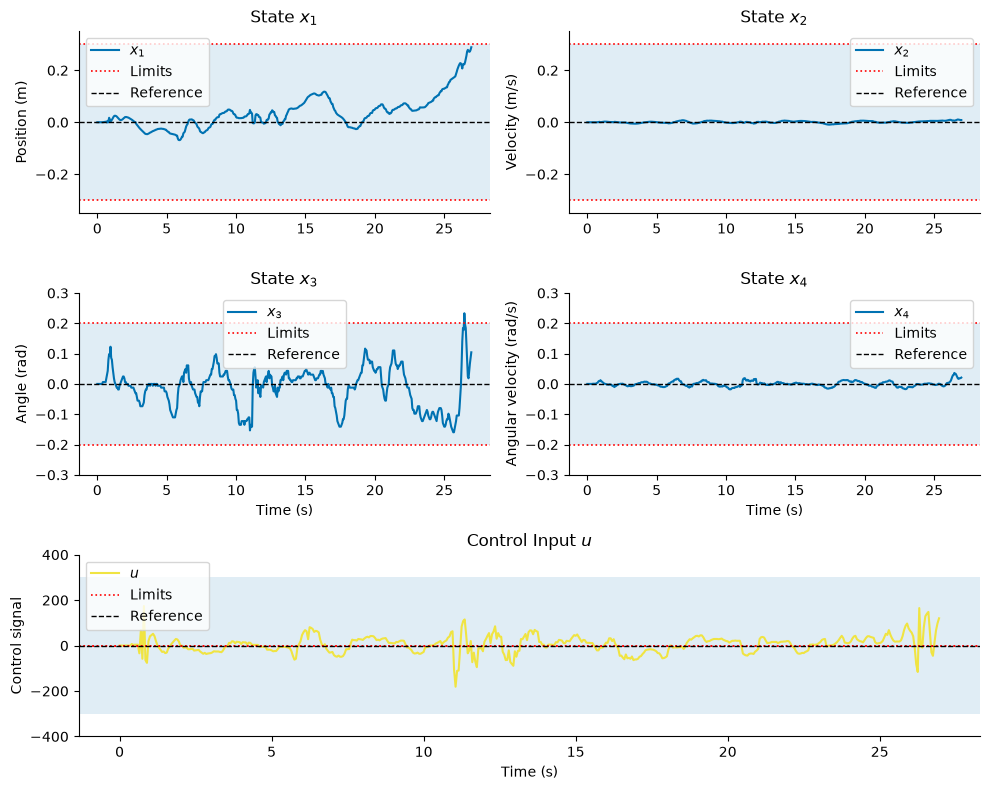

In [30]:
# Sampling period
T = 0.05  # seconds

# Number of samples
n = len(df)

# Generate time vector
t = np.arange(n) * T

# Create figure with GridSpec
fig = plt.figure(figsize=(10, 8))

gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1])

axs = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[2, :])
]

# State configurations
states = ["x1", "x2", "x3", "x4"]

labels = [
    "Position (m)",
    "Velocity (m/s)",
    "Angle (rad)",
    "Angular velocity (rad/s)"
]

limits = [0.30, 0.30, 0.20, 0.20]

ylims = [
    (-0.35, 0.35),
    (-0.35, 0.35),
    (-0.30, 0.30),
    (-0.30, 0.30)
]

# Plot states
for i, state in enumerate(states):

    ax = axs[i]
    limit = limits[i]

    # State signal
    ax.plot(
        t,
        df[state],
        label=fr"$x_{i+1}$",
        color="#0072B2"
    )

    # Limits
    ax.axhline(
        -limit,
        color="red",
        linestyle=":",
        linewidth=1.2,
        label="Limits"
    )

    ax.axhline(
        limit,
        color="red",
        linestyle=":",
        linewidth=1.2
    )

    # Reference
    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Reference"
    )

    # Valid operating region
    ax.axhspan(
        -limit,
        limit,
        facecolor="#0072B2",
        alpha=0.12,
        zorder=0
    )

    ax.set_title(fr"State $x_{i+1}$")
    ax.set_ylabel(labels[i])
    ax.set_ylim(ylims[i])
    ax.legend()


# Control input u
ax = axs[4]

ax.plot(
    t,
    df["u"],
    label=r"$u$",
    color="#F0E442"
)

# Control limits
ax.axhline(
    -0.30,
    color="red",
    linestyle=":",
    linewidth=1.2,
    label="Limits"
)

ax.axhline(
    0.30,
    color="red",
    linestyle=":",
    linewidth=1.2
)

# Reference
ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Reference"
)

# Valid operating region
ax.axhspan(
    -300,
    300,
    facecolor="#0072B2",
    alpha=0.12,
    zorder=0
)

ax.set_title(r"Control Input $u$")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Control signal")
ax.set_ylim([-400,400])
ax.legend()

# Remove top and right borders
for ax in axs:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Time labels
axs[2].set_xlabel("Time (s)")
axs[3].set_xlabel("Time (s)")

# Adjust layout
fig.tight_layout()

plt.show()

In [31]:
df = pd.read_csv('Backup/Data_B.csv', header=None).T
df.columns = ["n", "x1_kf", "x2_kf", "x3_kf", "x4_kf","x1_real", "x3_real", "u", "INPUT", "ruido","Latency", "t", "k"]
df = df[["x1_real", "x2_kf", "x3_real", "x4_kf", "u"]]
df.columns = ["x1", "x2", "x3", "x4", "u"]
df = df.apply(pd.to_numeric, errors="coerce")
df.head()

,x1,x2,x3,x4,u
0,0.0000,0.00000,0.024544,0.002454,30.0
1,0.0030,0.00030,0.012272,0.001227,22.0
2,0.0052,0.00052,0.006136,0.000614,12.0
3,0.0064,0.00064,0.000000,0.000000,-1.0
4,0.0063,0.00063,-0.006136,-0.000614,-13.0


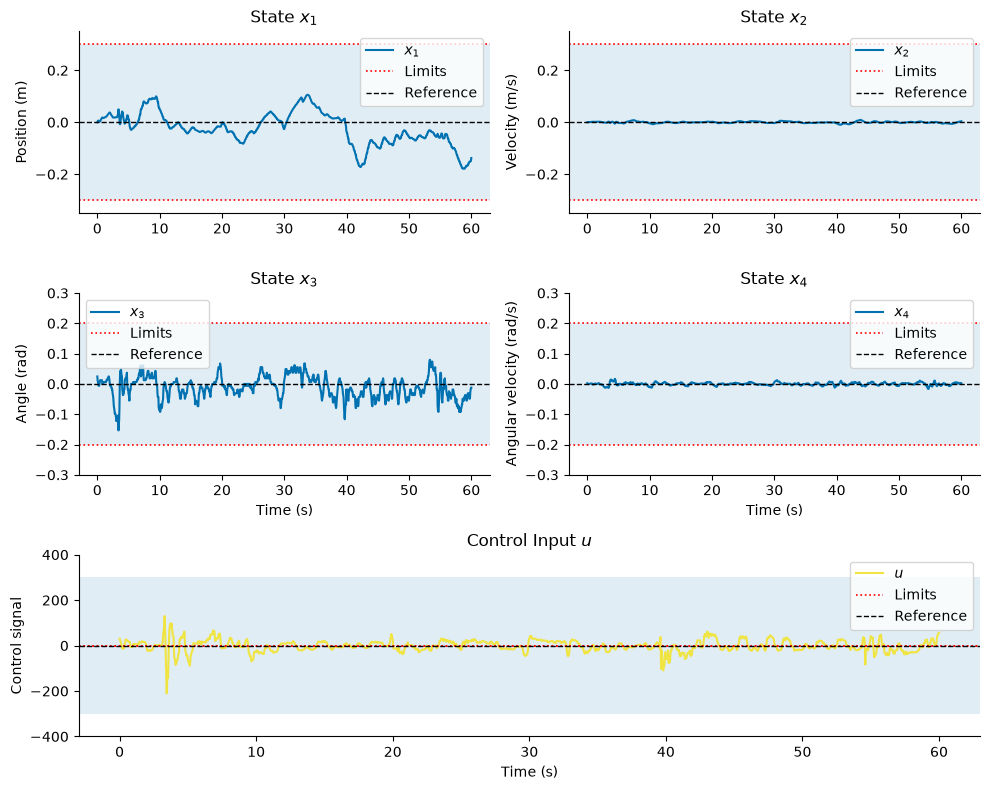

In [32]:
# Sampling period
T = 0.05  # seconds

# Number of samples
n = len(df)

# Generate time vector
t = np.arange(n) * T

# Create figure with GridSpec
fig = plt.figure(figsize=(10, 8))

gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1])

axs = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[2, :])
]

# State configurations
states = ["x1", "x2", "x3", "x4"]

labels = [
    "Position (m)",
    "Velocity (m/s)",
    "Angle (rad)",
    "Angular velocity (rad/s)"
]

limits = [0.30, 0.30, 0.20, 0.20]

ylims = [
    (-0.35, 0.35),
    (-0.35, 0.35),
    (-0.30, 0.30),
    (-0.30, 0.30)
]

# Plot states
for i, state in enumerate(states):

    ax = axs[i]
    limit = limits[i]

    # State signal
    ax.plot(
        t,
        df[state],
        label=fr"$x_{i+1}$",
        color="#0072B2"
    )

    # Limits
    ax.axhline(
        -limit,
        color="red",
        linestyle=":",
        linewidth=1.2,
        label="Limits"
    )

    ax.axhline(
        limit,
        color="red",
        linestyle=":",
        linewidth=1.2
    )

    # Reference
    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Reference"
    )

    # Valid operating region
    ax.axhspan(
        -limit,
        limit,
        facecolor="#0072B2",
        alpha=0.12,
        zorder=0
    )

    ax.set_title(fr"State $x_{i+1}$")
    ax.set_ylabel(labels[i])
    ax.set_ylim(ylims[i])
    ax.legend()


# Control input u
ax = axs[4]

ax.plot(
    t,
    df["u"],
    label=r"$u$",
    color="#F0E442"
)

# Control limits
ax.axhline(
    -0.30,
    color="red",
    linestyle=":",
    linewidth=1.2,
    label="Limits"
)

ax.axhline(
    0.30,
    color="red",
    linestyle=":",
    linewidth=1.2
)

# Reference
ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Reference"
)

# Valid operating region
ax.axhspan(
    -300,
    300,
    facecolor="#0072B2",
    alpha=0.12,
    zorder=0
)

ax.set_title(r"Control Input $u$")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Control signal")
ax.set_ylim([-400,400])
ax.legend()

# Remove top and right borders
for ax in axs:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Time labels
axs[2].set_xlabel("Time (s)")
axs[3].set_xlabel("Time (s)")

# Adjust layout
fig.tight_layout()

plt.show()

In [33]:
df = pd.read_csv('Backup/Data_C.csv', header=None).T
df.columns = ["n", "x1_kf", "x2_kf", "x3_kf", "x4_kf","x1_real", "x3_real", "u", "INPUT", "ruido","Latency", "t", "k"]
df = df[["x1_real", "x2_kf", "x3_real", "x4_kf", "u"]]
df.columns = ["x1", "x2", "x3", "x4", "u"]
df = df.apply(pd.to_numeric, errors="coerce")
df.head()

,x1,x2,x3,x4,u
0,0.0000,0.00000,0.024544,0.002454,30.0
1,0.0030,0.00030,0.012272,0.001227,22.0
2,0.0052,0.00052,0.006136,0.000614,12.0
3,0.0064,0.00064,0.000000,0.000000,-1.0
4,0.0063,0.00063,-0.006136,-0.000614,-13.0


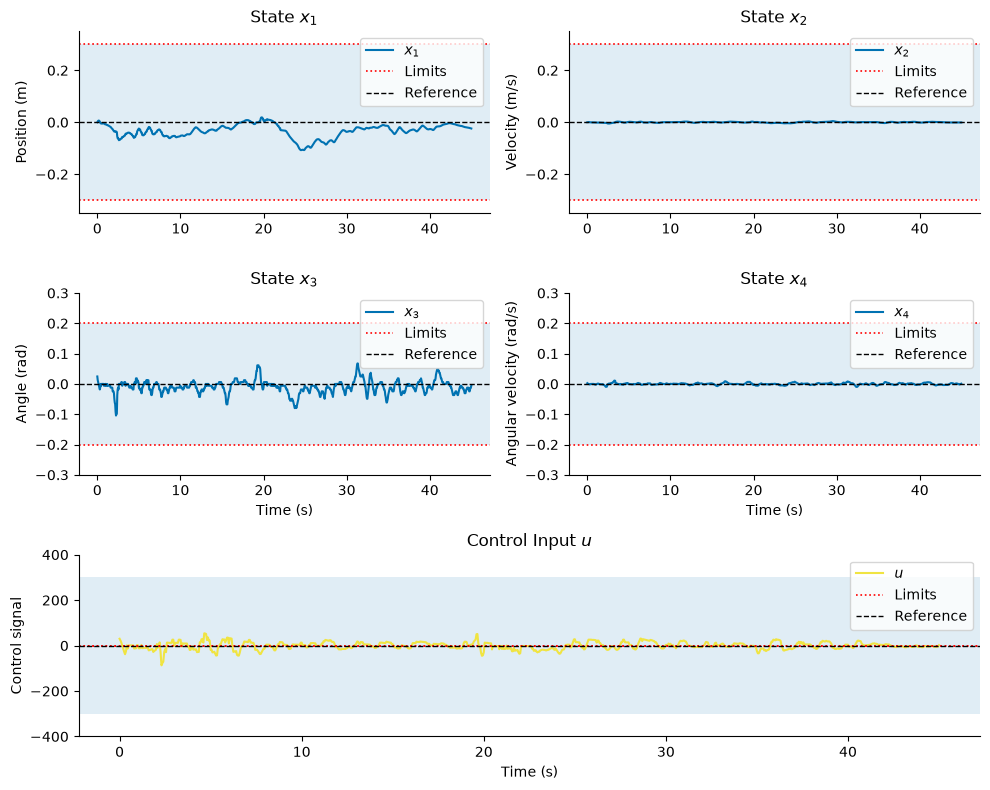

In [34]:
# Sampling period
T = 0.05  # seconds

# Number of samples
n = len(df)

# Generate time vector
t = np.arange(n) * T

# Create figure with GridSpec
fig = plt.figure(figsize=(10, 8))

gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1])

axs = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[2, :])
]

# State configurations
states = ["x1", "x2", "x3", "x4"]

labels = [
    "Position (m)",
    "Velocity (m/s)",
    "Angle (rad)",
    "Angular velocity (rad/s)"
]

limits = [0.30, 0.30, 0.20, 0.20]

ylims = [
    (-0.35, 0.35),
    (-0.35, 0.35),
    (-0.30, 0.30),
    (-0.30, 0.30)
]

# Plot states
for i, state in enumerate(states):

    ax = axs[i]
    limit = limits[i]

    # State signal
    ax.plot(
        t,
        df[state],
        label=fr"$x_{i+1}$",
        color="#0072B2"
    )

    # Limits
    ax.axhline(
        -limit,
        color="red",
        linestyle=":",
        linewidth=1.2,
        label="Limits"
    )

    ax.axhline(
        limit,
        color="red",
        linestyle=":",
        linewidth=1.2
    )

    # Reference
    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Reference"
    )

    # Valid operating region
    ax.axhspan(
        -limit,
        limit,
        facecolor="#0072B2",
        alpha=0.12,
        zorder=0
    )

    ax.set_title(fr"State $x_{i+1}$")
    ax.set_ylabel(labels[i])
    ax.set_ylim(ylims[i])
    ax.legend()


# Control input u
ax = axs[4]

ax.plot(
    t,
    df["u"],
    label=r"$u$",
    color="#F0E442"
)

# Control limits
ax.axhline(
    -0.30,
    color="red",
    linestyle=":",
    linewidth=1.2,
    label="Limits"
)

ax.axhline(
    0.30,
    color="red",
    linestyle=":",
    linewidth=1.2
)

# Reference
ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Reference"
)

# Valid operating region
ax.axhspan(
    -300,
    300,
    facecolor="#0072B2",
    alpha=0.12,
    zorder=0
)

ax.set_title(r"Control Input $u$")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Control signal")
ax.set_ylim([-400,400])
ax.legend()

# Remove top and right borders
for ax in axs:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Time labels
axs[2].set_xlabel("Time (s)")
axs[3].set_xlabel("Time (s)")

# Adjust layout
fig.tight_layout()

plt.show()

In [35]:
df = pd.read_csv('Backup/Data_D.csv', header=None).T
df.columns = ["n", "x1_kf", "x2_kf", "x3_kf", "x4_kf","x1_real", "x3_real", "u", "INPUT", "ruido","Latency", "t", "k"]
df = df[["x1_real", "x2_kf", "x3_real", "x4_kf", "u"]]
df.columns = ["x1", "x2", "x3", "x4", "u"]
df = df.apply(pd.to_numeric, errors="coerce")
df.head()

,x1,x2,x3,x4,u
0,0.0000,0.00000,0.024544,0.002454,122.0
1,0.0122,0.00122,-0.024544,-0.002454,-61.0
2,0.0061,0.00061,-0.042951,-0.004295,-142.0
3,-0.0081,-0.00081,-0.049087,-0.004909,-150.0
4,-0.0231,-0.00231,-0.061359,-0.006136,-87.0


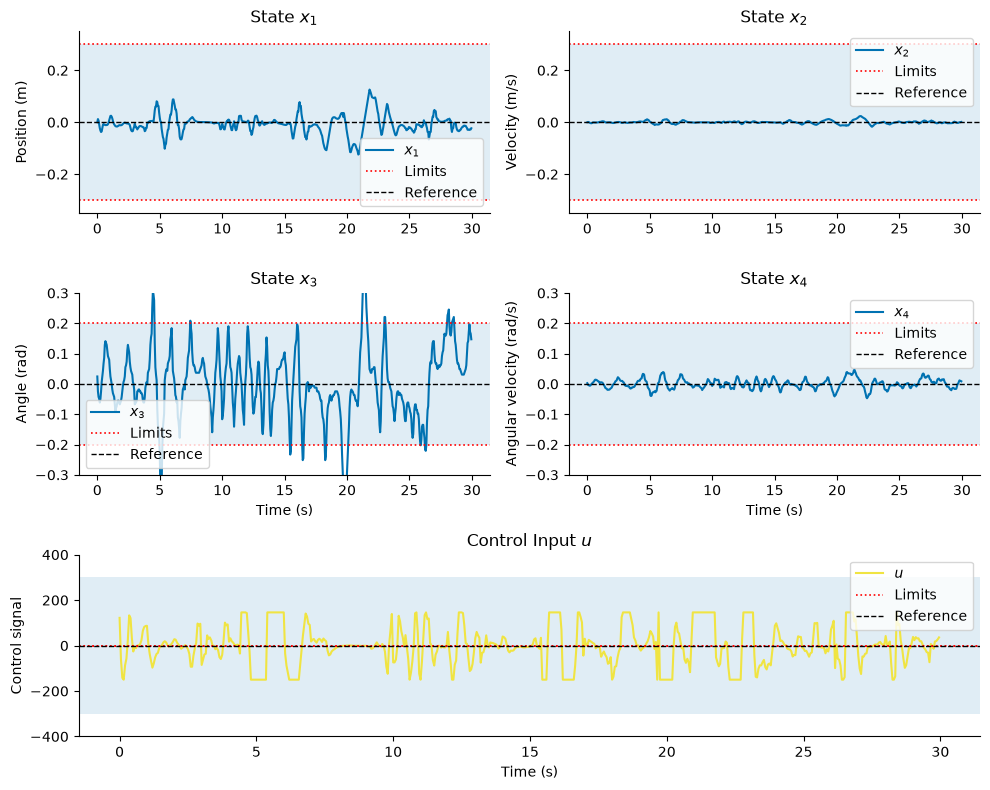

In [36]:
# Sampling period
T = 0.05  # seconds

# Number of samples
n = len(df)

# Generate time vector
t = np.arange(n) * T

# Create figure with GridSpec
fig = plt.figure(figsize=(10, 8))

gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1])

axs = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[2, :])
]

# State configurations
states = ["x1", "x2", "x3", "x4"]

labels = [
    "Position (m)",
    "Velocity (m/s)",
    "Angle (rad)",
    "Angular velocity (rad/s)"
]

limits = [0.30, 0.30, 0.20, 0.20]

ylims = [
    (-0.35, 0.35),
    (-0.35, 0.35),
    (-0.30, 0.30),
    (-0.30, 0.30)
]

# Plot states
for i, state in enumerate(states):

    ax = axs[i]
    limit = limits[i]

    # State signal
    ax.plot(
        t,
        df[state],
        label=fr"$x_{i+1}$",
        color="#0072B2"
    )

    # Limits
    ax.axhline(
        -limit,
        color="red",
        linestyle=":",
        linewidth=1.2,
        label="Limits"
    )

    ax.axhline(
        limit,
        color="red",
        linestyle=":",
        linewidth=1.2
    )

    # Reference
    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Reference"
    )

    # Valid operating region
    ax.axhspan(
        -limit,
        limit,
        facecolor="#0072B2",
        alpha=0.12,
        zorder=0
    )

    ax.set_title(fr"State $x_{i+1}$")
    ax.set_ylabel(labels[i])
    ax.set_ylim(ylims[i])
    ax.legend()


# Control input u
ax = axs[4]

ax.plot(
    t,
    df["u"],
    label=r"$u$",
    color="#F0E442"
)

# Control limits
ax.axhline(
    -0.30,
    color="red",
    linestyle=":",
    linewidth=1.2,
    label="Limits"
)

ax.axhline(
    0.30,
    color="red",
    linestyle=":",
    linewidth=1.2
)

# Reference
ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Reference"
)

# Valid operating region
ax.axhspan(
    -300,
    300,
    facecolor="#0072B2",
    alpha=0.12,
    zorder=0
)

ax.set_title(r"Control Input $u$")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Control signal")
ax.set_ylim([-400,400])
ax.legend()

# Remove top and right borders
for ax in axs:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Time labels
axs[2].set_xlabel("Time (s)")
axs[3].set_xlabel("Time (s)")

# Adjust layout
fig.tight_layout()

plt.show()

In [37]:
df = pd.read_csv('Backup/Data_E.csv', header=None).T
df.columns = ["n", "x1_kf", "x2_kf", "x3_kf", "x4_kf","x1_real", "x3_real", "u", "INPUT", "ruido","Latency", "t", "k"]
df = df[["x1_real", "x2_kf", "x3_real", "x4_kf", "u"]]
df.columns = ["x1", "x2", "x3", "x4", "u"]
df = df.apply(pd.to_numeric, errors="coerce")
df.head()

,x1,x2,x3,x4,u
0,0.0000,0.00000,0.024544,0.002454,30.0
1,0.0030,0.00030,0.018408,0.001841,41.0
2,0.0071,0.00071,0.006136,0.000614,12.0
3,0.0083,0.00083,0.000000,0.000000,-1.0
4,0.0082,0.00082,-0.006136,-0.000614,-15.0


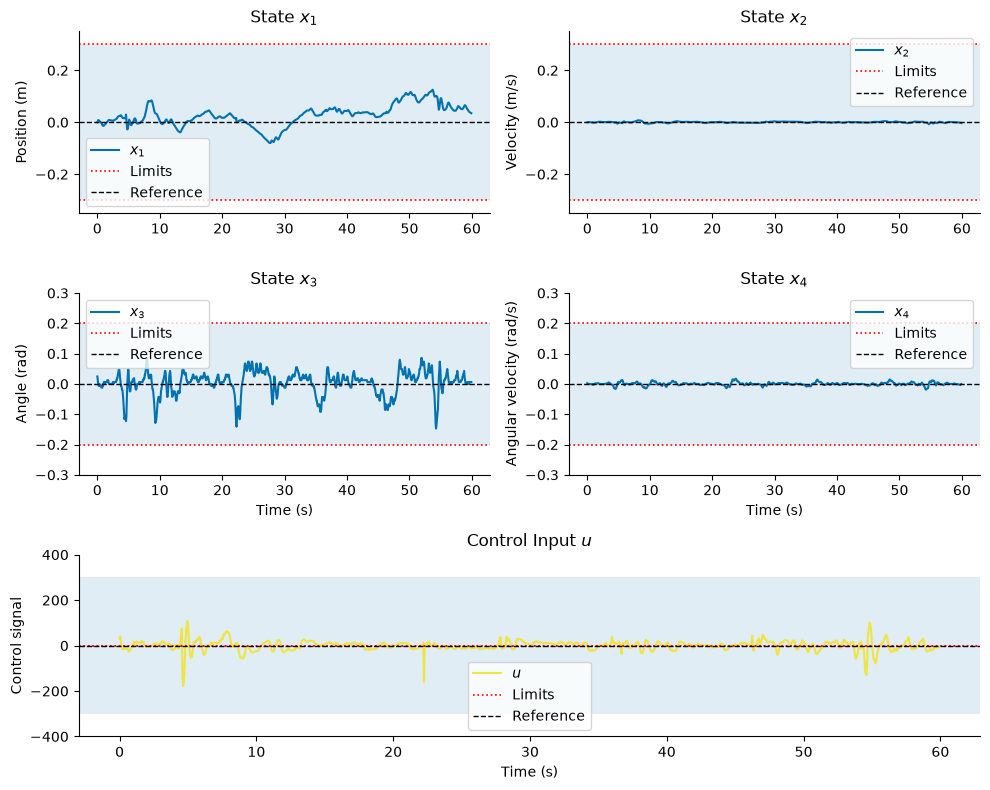

In [38]:
# Sampling period
T = 0.05  # seconds

# Number of samples
n = len(df)

# Generate time vector
t = np.arange(n) * T

# Create figure with GridSpec
fig = plt.figure(figsize=(10, 8))

gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1])

axs = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[2, :])
]

# State configurations
states = ["x1", "x2", "x3", "x4"]

labels = [
    "Position (m)",
    "Velocity (m/s)",
    "Angle (rad)",
    "Angular velocity (rad/s)"
]

limits = [0.30, 0.30, 0.20, 0.20]

ylims = [
    (-0.35, 0.35),
    (-0.35, 0.35),
    (-0.30, 0.30),
    (-0.30, 0.30)
]

# Plot states
for i, state in enumerate(states):

    ax = axs[i]
    limit = limits[i]

    # State signal
    ax.plot(
        t,
        df[state],
        label=fr"$x_{i+1}$",
        color="#0072B2"
    )

    # Limits
    ax.axhline(
        -limit,
        color="red",
        linestyle=":",
        linewidth=1.2,
        label="Limits"
    )

    ax.axhline(
        limit,
        color="red",
        linestyle=":",
        linewidth=1.2
    )

    # Reference
    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Reference"
    )

    # Valid operating region
    ax.axhspan(
        -limit,
        limit,
        facecolor="#0072B2",
        alpha=0.12,
        zorder=0
    )

    ax.set_title(fr"State $x_{i+1}$")
    ax.set_ylabel(labels[i])
    ax.set_ylim(ylims[i])
    ax.legend()


# Control input u
ax = axs[4]

ax.plot(
    t,
    df["u"],
    label=r"$u$",
    color="#F0E442"
)

# Control limits
ax.axhline(
    -0.30,
    color="red",
    linestyle=":",
    linewidth=1.2,
    label="Limits"
)

ax.axhline(
    0.30,
    color="red",
    linestyle=":",
    linewidth=1.2
)

# Reference
ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Reference"
)

# Valid operating region
ax.axhspan(
    -300,
    300,
    facecolor="#0072B2",
    alpha=0.12,
    zorder=0
)

ax.set_title(r"Control Input $u$")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Control signal")
ax.set_ylim([-400,400])
ax.legend()

# Remove top and right borders
for ax in axs:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Time labels
axs[2].set_xlabel("Time (s)")
axs[3].set_xlabel("Time (s)")

# Adjust layout
fig.tight_layout()

plt.show()

In [39]:
df = pd.read_csv('Backup/Data_A50ms.csv', header=None).T
df.columns = ["n", "x1_kf", "x2_kf", "x3_kf", "x4_kf","x1_real", "x3_real", "u", "INPUT", "ruido","Latency", "t", "k"]
df = df[["x1_real", "x2_kf", "x3_real", "x4_kf", "u"]]
df.columns = ["x1", "x2", "x3", "x4", "u"]
df = df.apply(pd.to_numeric, errors="coerce")
df.head()

,x1,x2,x3,x4,u
0,0.0000,0.00000,0.024544,0.002454,106.0
1,0.0106,0.00106,-0.006136,-0.000614,-19.0
2,0.0087,0.00087,-0.006136,-0.000614,-20.0
3,0.0067,0.00067,0.006136,0.000614,18.0
4,0.0085,0.00085,0.006136,0.000614,19.0


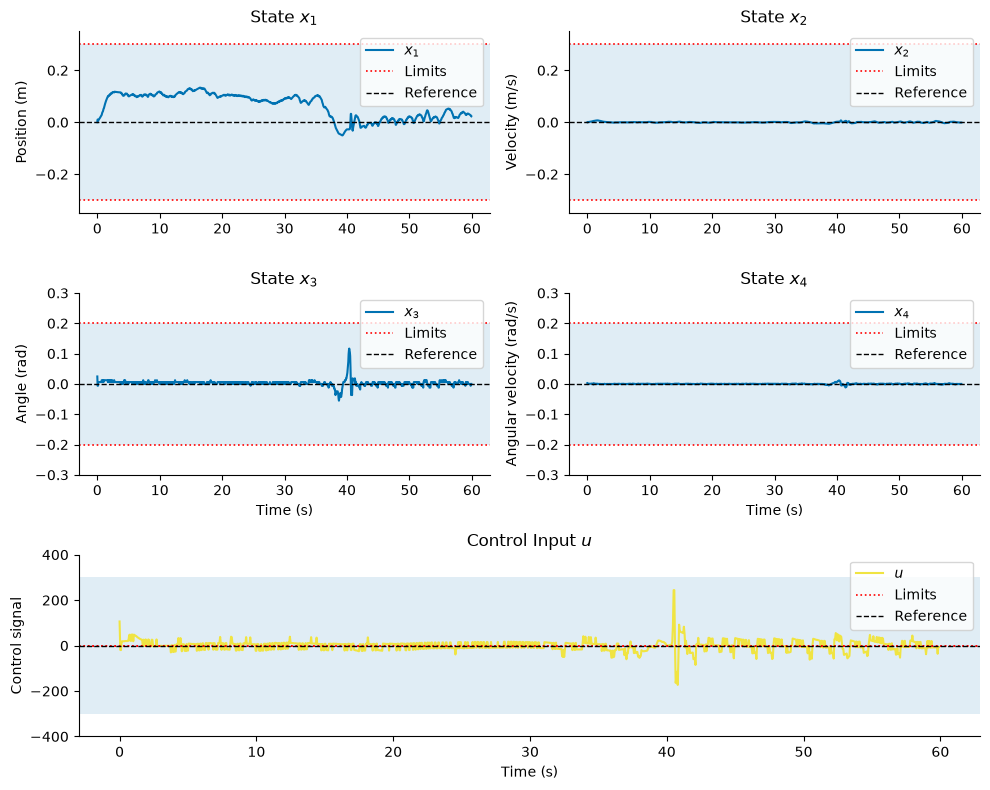

In [40]:
# Sampling period
T = 0.05  # seconds

# Number of samples
n = len(df)

# Generate time vector
t = np.arange(n) * T

# Create figure with GridSpec
fig = plt.figure(figsize=(10, 8))

gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1])

axs = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[2, :])
]

# State configurations
states = ["x1", "x2", "x3", "x4"]

labels = [
    "Position (m)",
    "Velocity (m/s)",
    "Angle (rad)",
    "Angular velocity (rad/s)"
]

limits = [0.30, 0.30, 0.20, 0.20]

ylims = [
    (-0.35, 0.35),
    (-0.35, 0.35),
    (-0.30, 0.30),
    (-0.30, 0.30)
]

# Plot states
for i, state in enumerate(states):

    ax = axs[i]
    limit = limits[i]

    # State signal
    ax.plot(
        t,
        df[state],
        label=fr"$x_{i+1}$",
        color="#0072B2"
    )

    # Limits
    ax.axhline(
        -limit,
        color="red",
        linestyle=":",
        linewidth=1.2,
        label="Limits"
    )

    ax.axhline(
        limit,
        color="red",
        linestyle=":",
        linewidth=1.2
    )

    # Reference
    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Reference"
    )

    # Valid operating region
    ax.axhspan(
        -limit,
        limit,
        facecolor="#0072B2",
        alpha=0.12,
        zorder=0
    )

    ax.set_title(fr"State $x_{i+1}$")
    ax.set_ylabel(labels[i])
    ax.set_ylim(ylims[i])
    ax.legend()


# Control input u
ax = axs[4]

ax.plot(
    t,
    df["u"],
    label=r"$u$",
    color="#F0E442"
)

# Control limits
ax.axhline(
    -0.30,
    color="red",
    linestyle=":",
    linewidth=1.2,
    label="Limits"
)

ax.axhline(
    0.30,
    color="red",
    linestyle=":",
    linewidth=1.2
)

# Reference
ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Reference"
)

# Valid operating region
ax.axhspan(
    -300,
    300,
    facecolor="#0072B2",
    alpha=0.12,
    zorder=0
)

ax.set_title(r"Control Input $u$")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Control signal")
ax.set_ylim([-400,400])
ax.legend()

# Remove top and right borders
for ax in axs:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Time labels
axs[2].set_xlabel("Time (s)")
axs[3].set_xlabel("Time (s)")

# Adjust layout
fig.tight_layout()

plt.show()

In [41]:
df = pd.read_csv('Backup/Data_B50ms.csv', header=None).T
df.columns = ["n", "x1_kf", "x2_kf", "x3_kf", "x4_kf","x1_real", "x3_real", "u", "INPUT", "ruido","Latency", "t", "k"]
df = df[["x1_real", "x2_kf", "x3_real", "x4_kf", "u"]]
df.columns = ["x1", "x2", "x3", "x4", "u"]
df = df.apply(pd.to_numeric, errors="coerce")
df.head()

,x1,x2,x3,x4,u
0,0.0000,0.00000,0.024544,0.002454,106.0
1,0.0106,0.00106,-0.012272,-0.001227,-33.0
2,0.0073,0.00073,-0.018408,-0.001841,-50.0
3,0.0023,0.00023,-0.018408,-0.001841,-52.0
4,-0.0029,-0.00029,-0.030680,-0.003068,-97.0


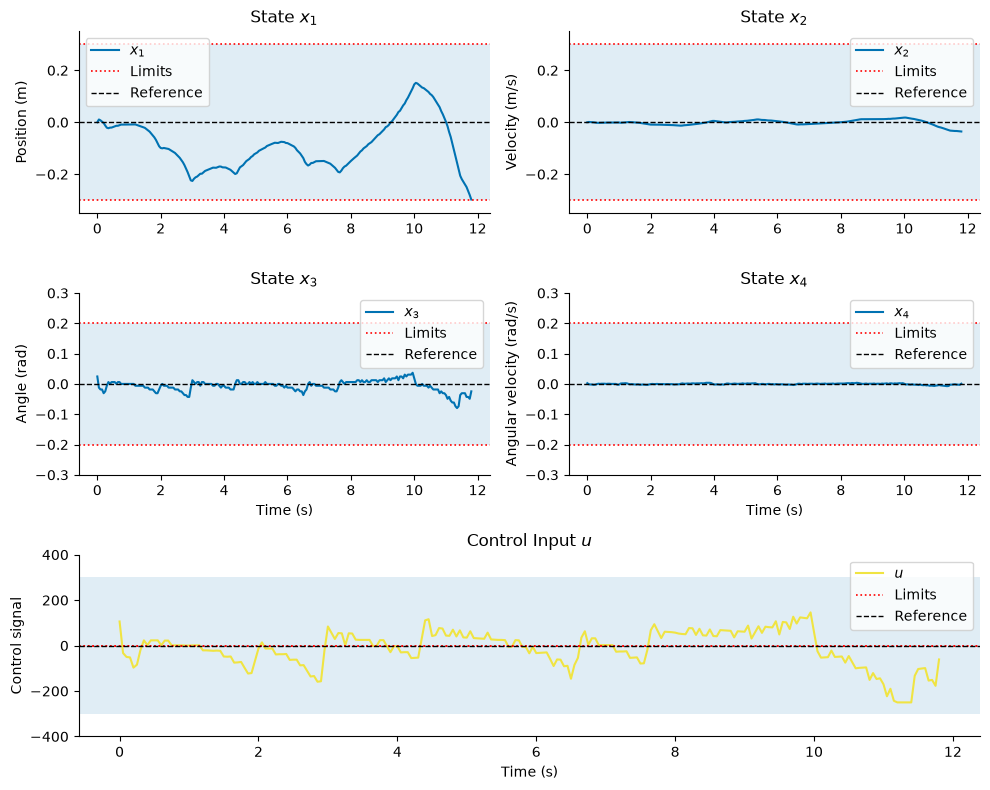

In [42]:
# Sampling period
T = 0.05  # seconds

# Number of samples
n = len(df)

# Generate time vector
t = np.arange(n) * T

# Create figure with GridSpec
fig = plt.figure(figsize=(10, 8))

gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1])

axs = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[2, :])
]

# State configurations
states = ["x1", "x2", "x3", "x4"]

labels = [
    "Position (m)",
    "Velocity (m/s)",
    "Angle (rad)",
    "Angular velocity (rad/s)"
]

limits = [0.30, 0.30, 0.20, 0.20]

ylims = [
    (-0.35, 0.35),
    (-0.35, 0.35),
    (-0.30, 0.30),
    (-0.30, 0.30)
]

# Plot states
for i, state in enumerate(states):

    ax = axs[i]
    limit = limits[i]

    # State signal
    ax.plot(
        t,
        df[state],
        label=fr"$x_{i+1}$",
        color="#0072B2"
    )

    # Limits
    ax.axhline(
        -limit,
        color="red",
        linestyle=":",
        linewidth=1.2,
        label="Limits"
    )

    ax.axhline(
        limit,
        color="red",
        linestyle=":",
        linewidth=1.2
    )

    # Reference
    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Reference"
    )

    # Valid operating region
    ax.axhspan(
        -limit,
        limit,
        facecolor="#0072B2",
        alpha=0.12,
        zorder=0
    )

    ax.set_title(fr"State $x_{i+1}$")
    ax.set_ylabel(labels[i])
    ax.set_ylim(ylims[i])
    ax.legend()


# Control input u
ax = axs[4]

ax.plot(
    t,
    df["u"],
    label=r"$u$",
    color="#F0E442"
)

# Control limits
ax.axhline(
    -0.30,
    color="red",
    linestyle=":",
    linewidth=1.2,
    label="Limits"
)

ax.axhline(
    0.30,
    color="red",
    linestyle=":",
    linewidth=1.2
)

# Reference
ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Reference"
)

# Valid operating region
ax.axhspan(
    -300,
    300,
    facecolor="#0072B2",
    alpha=0.12,
    zorder=0
)

ax.set_title(r"Control Input $u$")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Control signal")
ax.set_ylim([-400,400])
ax.legend()

# Remove top and right borders
for ax in axs:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Time labels
axs[2].set_xlabel("Time (s)")
axs[3].set_xlabel("Time (s)")

# Adjust layout
fig.tight_layout()

plt.show()

In [43]:
df = pd.read_csv('Backup/Data_C50ms.csv', header=None).T
df.columns = ["n", "x1_kf", "x2_kf", "x3_kf", "x4_kf","x1_real", "x3_real", "u", "INPUT", "ruido","Latency", "t", "k"]
df = df[["x1_real", "x2_kf", "x3_real", "x4_kf", "u"]]
df.columns = ["x1", "x2", "x3", "x4", "u"]
df = df.apply(pd.to_numeric, errors="coerce")
df.head()

,x1,x2,x3,x4,u
0,0.0000,0.00000,0.024544,0.002454,106.0
1,0.0106,0.00106,-0.030680,-0.003068,-58.0
2,0.0048,0.00048,-0.024544,-0.002454,-46.0
3,0.0002,0.00002,-0.018408,-0.001841,-33.0
4,-0.0031,-0.00031,-0.012272,-0.001227,-21.0


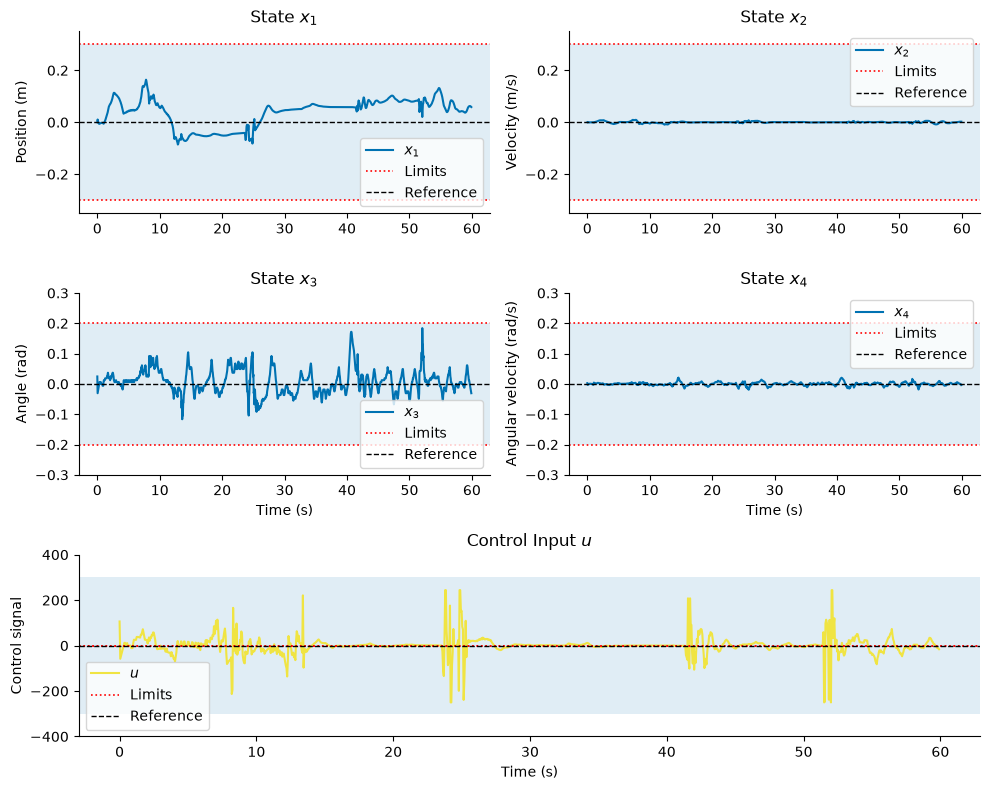

In [44]:
# Sampling period
T = 0.05  # seconds

# Number of samples
n = len(df)

# Generate time vector
t = np.arange(n) * T

# Create figure with GridSpec
fig = plt.figure(figsize=(10, 8))

gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1])

axs = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[2, :])
]

# State configurations
states = ["x1", "x2", "x3", "x4"]

labels = [
    "Position (m)",
    "Velocity (m/s)",
    "Angle (rad)",
    "Angular velocity (rad/s)"
]

limits = [0.30, 0.30, 0.20, 0.20]

ylims = [
    (-0.35, 0.35),
    (-0.35, 0.35),
    (-0.30, 0.30),
    (-0.30, 0.30)
]

# Plot states
for i, state in enumerate(states):

    ax = axs[i]
    limit = limits[i]

    # State signal
    ax.plot(
        t,
        df[state],
        label=fr"$x_{i+1}$",
        color="#0072B2"
    )

    # Limits
    ax.axhline(
        -limit,
        color="red",
        linestyle=":",
        linewidth=1.2,
        label="Limits"
    )

    ax.axhline(
        limit,
        color="red",
        linestyle=":",
        linewidth=1.2
    )

    # Reference
    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Reference"
    )

    # Valid operating region
    ax.axhspan(
        -limit,
        limit,
        facecolor="#0072B2",
        alpha=0.12,
        zorder=0
    )

    ax.set_title(fr"State $x_{i+1}$")
    ax.set_ylabel(labels[i])
    ax.set_ylim(ylims[i])
    ax.legend()


# Control input u
ax = axs[4]

ax.plot(
    t,
    df["u"],
    label=r"$u$",
    color="#F0E442"
)

# Control limits
ax.axhline(
    -0.30,
    color="red",
    linestyle=":",
    linewidth=1.2,
    label="Limits"
)

ax.axhline(
    0.30,
    color="red",
    linestyle=":",
    linewidth=1.2
)

# Reference
ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Reference"
)

# Valid operating region
ax.axhspan(
    -300,
    300,
    facecolor="#0072B2",
    alpha=0.12,
    zorder=0
)

ax.set_title(r"Control Input $u$")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Control signal")
ax.set_ylim([-400,400])
ax.legend()

# Remove top and right borders
for ax in axs:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Time labels
axs[2].set_xlabel("Time (s)")
axs[3].set_xlabel("Time (s)")

# Adjust layout
fig.tight_layout()

plt.show()

In [45]:
df = pd.read_csv('Backup/Data_D50ms.csv', header=None).T
df.columns = ["n", "x1_kf", "x2_kf", "x3_kf", "x4_kf","x1_real", "x3_real", "u", "INPUT", "ruido","Latency", "t", "k"]
df = df[["x1_real", "x2_kf", "x3_real", "x4_kf", "u"]]
df.columns = ["x1", "x2", "x3", "x4", "u"]
df = df.apply(pd.to_numeric, errors="coerce")
df.head()

,x1,x2,x3,x4,u
0,0.0000,0.00000,0.024544,0.002454,106.0
1,0.0106,0.00106,-0.012272,-0.001227,-35.0
2,0.0071,0.00071,-0.024544,-0.002454,-69.0
3,0.0002,0.00002,-0.012272,-0.001227,-34.0
4,-0.0032,-0.00032,-0.018408,-0.001841,-54.0


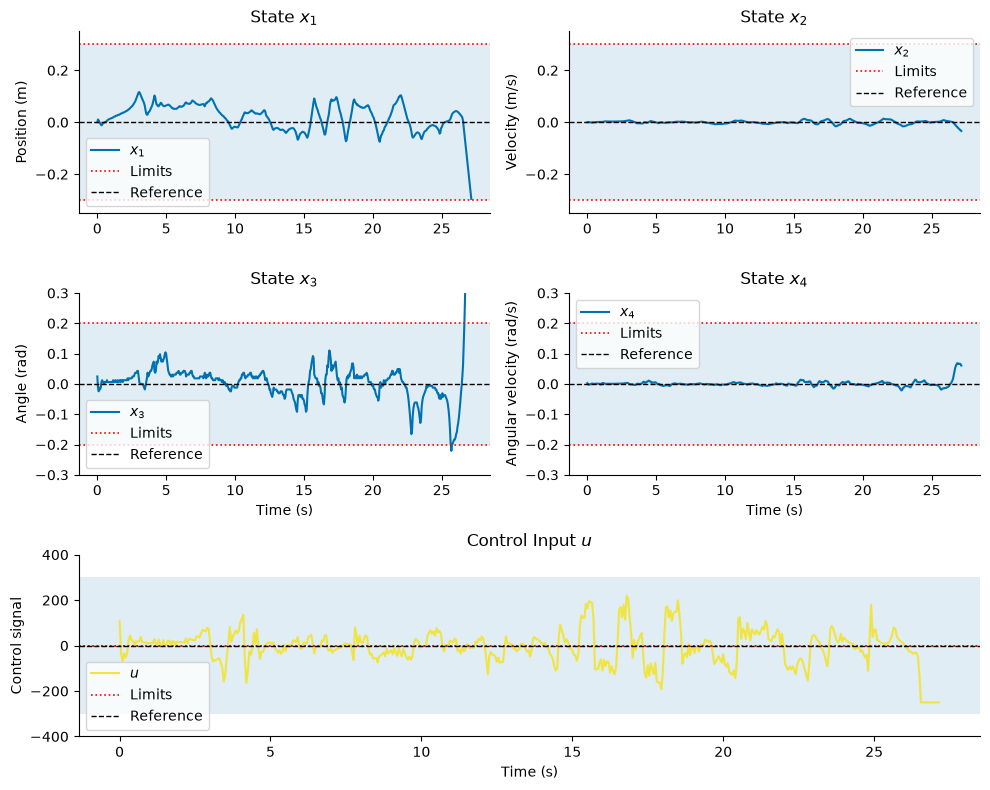

In [46]:
# Sampling period
T = 0.05  # seconds

# Number of samples
n = len(df)

# Generate time vector
t = np.arange(n) * T

# Create figure with GridSpec
fig = plt.figure(figsize=(10, 8))

gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1])

axs = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[2, :])
]

# State configurations
states = ["x1", "x2", "x3", "x4"]

labels = [
    "Position (m)",
    "Velocity (m/s)",
    "Angle (rad)",
    "Angular velocity (rad/s)"
]

limits = [0.30, 0.30, 0.20, 0.20]

ylims = [
    (-0.35, 0.35),
    (-0.35, 0.35),
    (-0.30, 0.30),
    (-0.30, 0.30)
]

# Plot states
for i, state in enumerate(states):

    ax = axs[i]
    limit = limits[i]

    # State signal
    ax.plot(
        t,
        df[state],
        label=fr"$x_{i+1}$",
        color="#0072B2"
    )

    # Limits
    ax.axhline(
        -limit,
        color="red",
        linestyle=":",
        linewidth=1.2,
        label="Limits"
    )

    ax.axhline(
        limit,
        color="red",
        linestyle=":",
        linewidth=1.2
    )

    # Reference
    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Reference"
    )

    # Valid operating region
    ax.axhspan(
        -limit,
        limit,
        facecolor="#0072B2",
        alpha=0.12,
        zorder=0
    )

    ax.set_title(fr"State $x_{i+1}$")
    ax.set_ylabel(labels[i])
    ax.set_ylim(ylims[i])
    ax.legend()


# Control input u
ax = axs[4]

ax.plot(
    t,
    df["u"],
    label=r"$u$",
    color="#F0E442"
)

# Control limits
ax.axhline(
    -0.30,
    color="red",
    linestyle=":",
    linewidth=1.2,
    label="Limits"
)

ax.axhline(
    0.30,
    color="red",
    linestyle=":",
    linewidth=1.2
)

# Reference
ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Reference"
)

# Valid operating region
ax.axhspan(
    -300,
    300,
    facecolor="#0072B2",
    alpha=0.12,
    zorder=0
)

ax.set_title(r"Control Input $u$")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Control signal")
ax.set_ylim([-400,400])
ax.legend()

# Remove top and right borders
for ax in axs:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Time labels
axs[2].set_xlabel("Time (s)")
axs[3].set_xlabel("Time (s)")

# Adjust layout
fig.tight_layout()

plt.show()

In [47]:
df = pd.read_csv('Backup/Data_E50ms.csv', header=None).T
df.columns = ["n", "x1_kf", "x2_kf", "x3_kf", "x4_kf","x1_real", "x3_real", "u", "INPUT", "ruido","Latency", "t", "k"]
df = df[["x1_real", "x2_kf", "x3_real", "x4_kf", "u"]]
df.columns = ["x1", "x2", "x3", "x4", "u"]
df = df.apply(pd.to_numeric, errors="coerce")
df.head()

,x1,x2,x3,x4,u
0,0.000,0.0000,0.024544,0.002454,110.0
1,0.011,0.0011,-0.055223,-0.005522,-80.0
2,0.003,0.0003,-0.092039,-0.009204,-250.0
3,-0.022,-0.0022,-0.061359,-0.006136,-250.0
4,-0.047,-0.0047,-0.012272,-0.001227,-50.0


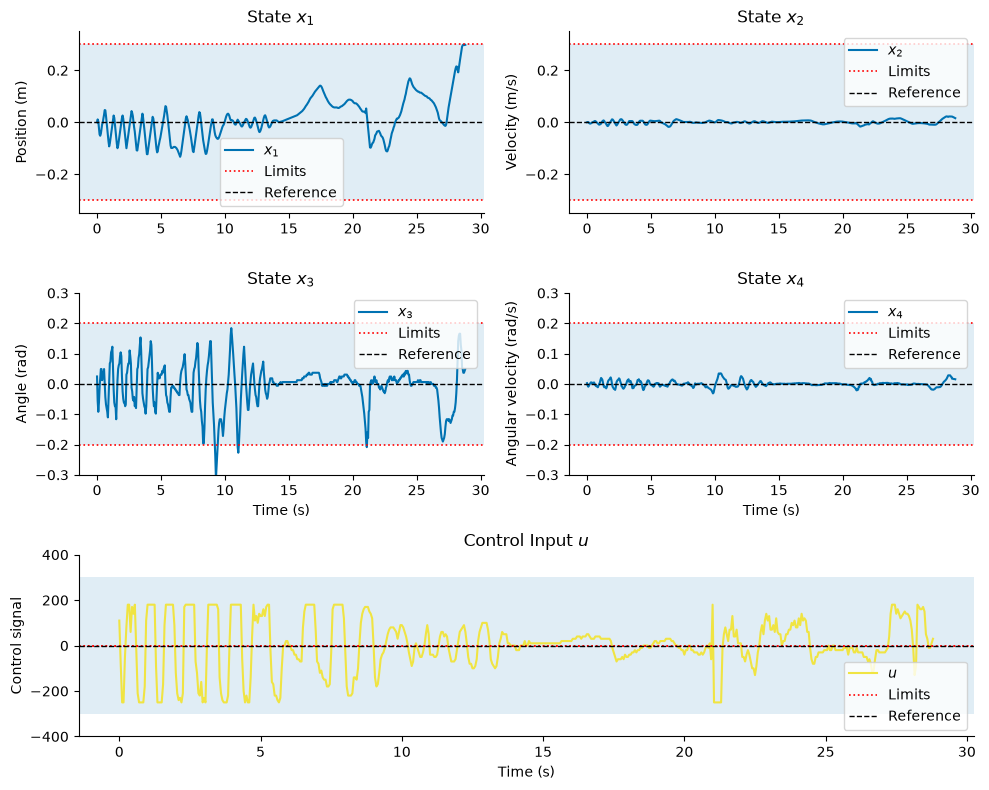

In [48]:
# Sampling period
T = 0.05  # seconds

# Number of samples
n = len(df)

# Generate time vector
t = np.arange(n) * T

# Create figure with GridSpec
fig = plt.figure(figsize=(10, 8))

gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1])

axs = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[2, :])
]

# State configurations
states = ["x1", "x2", "x3", "x4"]

labels = [
    "Position (m)",
    "Velocity (m/s)",
    "Angle (rad)",
    "Angular velocity (rad/s)"
]

limits = [0.30, 0.30, 0.20, 0.20]

ylims = [
    (-0.35, 0.35),
    (-0.35, 0.35),
    (-0.30, 0.30),
    (-0.30, 0.30)
]

# Plot states
for i, state in enumerate(states):

    ax = axs[i]
    limit = limits[i]

    # State signal
    ax.plot(
        t,
        df[state],
        label=fr"$x_{i+1}$",
        color="#0072B2"
    )

    # Limits
    ax.axhline(
        -limit,
        color="red",
        linestyle=":",
        linewidth=1.2,
        label="Limits"
    )

    ax.axhline(
        limit,
        color="red",
        linestyle=":",
        linewidth=1.2
    )

    # Reference
    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Reference"
    )

    # Valid operating region
    ax.axhspan(
        -limit,
        limit,
        facecolor="#0072B2",
        alpha=0.12,
        zorder=0
    )

    ax.set_title(fr"State $x_{i+1}$")
    ax.set_ylabel(labels[i])
    ax.set_ylim(ylims[i])
    ax.legend()


# Control input u
ax = axs[4]

ax.plot(
    t,
    df["u"],
    label=r"$u$",
    color="#F0E442"
)

# Control limits
ax.axhline(
    -0.30,
    color="red",
    linestyle=":",
    linewidth=1.2,
    label="Limits"
)

ax.axhline(
    0.30,
    color="red",
    linestyle=":",
    linewidth=1.2
)

# Reference
ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Reference"
)

# Valid operating region
ax.axhspan(
    -300,
    300,
    facecolor="#0072B2",
    alpha=0.12,
    zorder=0
)

ax.set_title(r"Control Input $u$")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Control signal")
ax.set_ylim([-400,400])
ax.legend()

# Remove top and right borders
for ax in axs:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Time labels
axs[2].set_xlabel("Time (s)")
axs[3].set_xlabel("Time (s)")

# Adjust layout
fig.tight_layout()

plt.show()